# GOA partial-polaron quantum master equation: a guided, runnable code walk-through (TCL2 → TCL3 → TCL4)

**Scope.** GOA bath → normal modes → reorganisation energy → partial-polaron filter → $\phi(t)$, $M(t)$, $C_X(t)$ → pair phase $K_{jk,j'k'}(t)$ → channel tensor $\mathcal C_{ab}(t)$ → finite-time TCL2 rates → $4\times4$ generator → populations. **Part II** continues from the *same* correlation functions to the higher orders: interaction picture → Liouville moments $\mathcal M_n$ → $\mathcal K_2$ (and its identity with the TCL2 generator) → exact multi-time bath moments → $\mathcal K_3$ → the ordered cumulant $\mathcal K_4$ → the size ratios $r_3, r_4$ → propagation of TCL2, TCL2+K3, TCL2+K4 and TCL234. No TEMPO calculations are run.

The notebook uses the package `goa_pqme` (one module per physical step, equations in the docstrings). **Every code cell is preceded by a cell with the mathematics it implements, and each code cell starts with a one-line comment repeating the key equation.** Every stage checks its result against an independent construction.

> **Similar-looking symbols:** $K_{jk,j'k'}$ is a dimensionless *pair phase* built from $\phi$. $\mathcal C_{ab}$ is the *bath-channel correlation tensor*. $\mathcal K_n$ ($n=2,3,4$) are the *TCL generators* (superoperators). $\mathcal M_n$ are *Liouville moments*. $r_n$ are *generator-size ratios*. The residual linear bath function (code: `linear`) is written $C_X(t)$, and the mixed one (code: `mixed`) is written $M(t)$.

**Conventions.** $\hbar=k_B=\omega_c=1$, site basis $(D,A)$, column-major $\operatorname{vec}\rho=(\rho_{00},\rho_{10},\rho_{01},\rho_{11})^T$ so that $\operatorname{vec}(X\rho Y)=(Y^T\otimes X)\operatorname{vec}\rho$. The bath is initially in equilibrium on the donor surface.

## 0. Set up: the package and its pipeline

The modules follow the chain of objects computed in this notebook:

$$\underbrace{(\omega_q,R_q,E_r)}_{\texttt{bath}}\;\to\;\underbrace{f_q,\;B,\;\lambda_p,\;\widetilde H_S,\;\{\phi,M,C_X\}}_{\texttt{frame}}\;\to\;\underbrace{\mathcal C_{ab}(t)\to W^{f,b}(t)\to\mathcal L_2(t)}_{\texttt{tcl2}}\;\to\;\underbrace{\langle B_{a_1}(t_1)\cdots B_{a_n}(t_n)\rangle}_{\texttt{moments}}\;\to\;\underbrace{\mathcal M_n\to\mathcal K_2,\mathcal K_3,\mathcal K_4,\;r_n}_{\texttt{tcl\_higher}}\;\to\;\underbrace{\rho(t)}_{\texttt{dynamics}}$$

In [1]:
# pipeline: bath -> frame -> tcl2 -> moments -> tcl_higher -> dynamics
from pathlib import Path
import sys, math
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
if not (ROOT / "goa_pqme" / "__init__.py").exists():
    raise FileNotFoundError("Open this notebook from the notebooks/ folder of the package (goa_pqme/ must be one level up).")
sys.path.insert(0, str(ROOT))
import goa_pqme as gp
from goa_pqme import bath, frame as frame_mod, tcl2, moments, tcl_higher, liouville, dynamics
np.set_printoptions(precision=6, suppress=True)
print("goa_pqme", gp.__version__, "from", ROOT)
for mod in (bath, frame_mod, tcl2, moments, tcl_higher, liouville, dynamics):
    print(f"  {mod.__name__:22s} {mod.__doc__.strip().splitlines()[0][:90]}")

goa_pqme 1.0.0 from <repository root>
  goa_pqme.bath          GOA bath: secondary-mode discretisation, normal modes, lab-frame correlation function.
  goa_pqme.frame         Partial-polaron frame (alpha, omega_h): filter, renormalisation, residual bath, system ope
  goa_pqme.tcl2          TCL2: residual correlation tensor C_ab(t), finite-time rate tensors, Schroedinger generato
  goa_pqme.moments       Exact multi-time moments  < B_{a_1}(t_1) B_{a_2}(t_2) ... B_{a_n}(t_n) >  of the residual 
  goa_pqme.tcl_higher    Time-convolutionless generators K2, K3, K4 (interaction picture, energy basis) at sparse t
  goa_pqme.liouville     Liouville-space conventions (used by every other module).
  goa_pqme.dynamics      Assemble the full generator, propagate, read out observables.


## 1. Choose a physical GOA case and one polaron filter

$$H=H_S+H_B+|A\rangle\langle A|\otimes X,\qquad H_S=\begin{pmatrix}\omega_{DA}&\Gamma\\\Gamma&E_r\end{pmatrix},\qquad H_B=\sum_q\tfrac12(p_q^2+\omega_q^2q_q^2),\qquad X=-\sum_q\omega_q^2R_qq_q .$$

The study case uses $\Omega=0.5$, 49 secondary modes ($\eta=\omega_c=1$), $y_0=0.75$, $\Gamma=0.2$, $\omega_{DA}=0$ and $\beta=\infty$. The filter parameters $\alpha=2$, $\omega_h=0.6$ are **illustrative**; change them to look at another frame. $\omega_h$ is the transformation crossover frequency, **not** the spectral cutoff $\omega_c$.

In [2]:
# model:  H_S = [[omega_DA, Gamma], [Gamma, E_r]],  coupling |A><A| X ;  frame (alpha, omega_h)
p = gp.ModelParams(Gamma=0.2, omega_DA=0.0, beta=np.inf, y0=0.75)     # Omega=0.5, N=50, omega_c=eta=1 by default
alpha, omega_h = 2.0, 0.6
tmax, dt = 8.0, 0.05
T = np.arange(0, tmax + dt/2, dt)
print(p)
print(f"case id: {gp.case_id(p)}   filter: alpha={alpha}, omega_h={omega_h}   grid: dt={dt}, tmax={tmax}")

ModelParams(Gamma=0.2, omega_DA=0.0, beta=inf, y0=0.75, Omega=0.5, N=50, omega_c=1.0, eta=1.0)
case id: G0p2_OD0_Binf_y0p75   filter: alpha=2.0, omega_h=0.6   grid: dt=0.05, tmax=8.0


## 2. Build the bath and derive $E_r$

Secondary modes (log discretisation of $J_{\rm sec}(\omega)=\eta\,\omega\,e^{-\omega/\omega_c}$, $N_s=N-1$):

$$\omega_j=-\omega_c\ln\frac{N_s+\frac12-j}{N_s},\qquad c_j=\omega_j\sqrt{\frac{2\eta\omega_c}{\pi N_s}} .$$

The primary and secondary coupled modes define a $50\times50$ force-constant matrix

$$K_{00}=\Omega^2+\sum_j\frac{c_j^2}{\omega_j^2},\quad K_{0j}=c_j,\quad K_{jj}=\omega_j^2,\qquad \mathbf K=\mathbf U\operatorname{diag}(\omega_q^2)\mathbf U^T .$$

The donor-to-acceptor shift is $\Delta\mathbf q=2\mathbf K^{-1}\mathbf f$ with $f_0=\Omega^2y_0$, so $R_q=(\mathbf U^T\Delta\mathbf q)_q$ and

$$\boxed{E_r=\tfrac12\sum_q\omega_q^2R_q^2=2\Omega^2y_0^2.}$$

The $R_q$ are displacements of **all** normal modes. The simple final formula follows from the counter-term (Schur complement of $\mathbf K$ on $q_0$ equals $\Omega^2$), not from the secondary modes being absent.

normal modes: 50  range: [0.0100, 4.5865]
E_r from 50 modes = 0.281250000000   2 Omega^2 y0^2 = 0.281250000000   |diff| = 1.3e-14
|R|^2 from package vs independent |dq|^2 (U orthogonal): 338.901749484144 338.901749484144


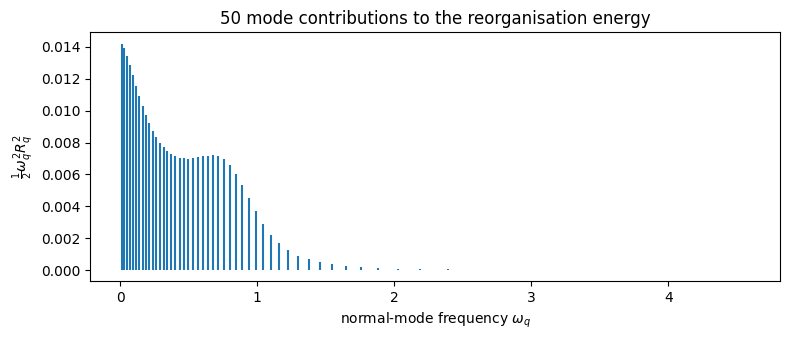

In [3]:
# K = U diag(w_q^2) U^T ;  R = U^T 2 K^{-1} (Omega^2 y0 e_0) ;  E_r = 1/2 sum_q w_q^2 R_q^2 = 2 Omega^2 y0^2
modes = gp.normal_modes(p)
omega, R, Er = modes.omega, modes.R, modes.Er
wsec, csec = bath.secondary_modes(p.N, p.eta, p.omega_c)
# independent rebuild of the Hessian and the shift
K = np.zeros((p.N, p.N)); K[0, 0] = p.Omega**2 + np.sum(csec**2 / wsec**2); K[0, 1:] = K[1:, 0] = csec; K[1:, 1:] = np.diag(wsec**2)
dq = 2 * np.linalg.solve(K, np.r_[p.Omega**2 * p.y0, np.zeros(p.N - 1)])
print('normal modes:', len(omega), ' range: [%.4f, %.4f]' % (omega.min(), omega.max()))
print('E_r from 50 modes = %.12f   2 Omega^2 y0^2 = %.12f   |diff| = %.1e' % (Er, p.Er, abs(Er - p.Er)))
print('|R|^2 from package vs independent |dq|^2 (U orthogonal): %.12f %.12f' % (np.sum(R**2), np.sum(dq**2)))
assert len(omega) == 50 and np.isclose(Er, p.Er, atol=1e-10) and np.isclose(np.sum(R**2), np.sum(dq**2))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.vlines(omega, 0, 0.5 * omega**2 * R**2, linewidth=1.5)
ax.set(xlabel=r'normal-mode frequency $\omega_q$', ylabel=r'$\frac{1}{2}\omega_q^2R_q^2$', title='50 mode contributions to the reorganisation energy')
plt.tight_layout(); plt.show()

## 3. Partial-polaron transformation and energy renormalisation

Mode-specific displacement fraction (filter):

$$f_q=W_h(\omega_q)=1-\exp[-(\omega_q/\omega_h)^\alpha].$$

With the acceptor-only unitary, the residual linear coupling is $X_f=-\sum_q(1-f_q)\omega_q^2R_qq_q$, and the transformed system Hamiltonian is

$$\widetilde H_S=\begin{pmatrix}\omega_{DA}&\Gamma B\\\Gamma B&E_r-\lambda_p\end{pmatrix}=U_e\operatorname{diag}(E_0,E_1)U_e^\dagger,\qquad
\lambda_p=\tfrac12\sum_q\omega_q^2R_q^2 f_q(2-f_q),\qquad B=e^{-\phi(0)/2}.$$

$\lambda_p$ follows from completing the square with the fractional shift $f_qR_q$: $\tfrac12\omega^2(fR)^2-\omega^2R(fR)=-\tfrac12\omega^2R^2f(2-f)$. The filter changes the perturbative partition, not the original GOA Hamiltonian.

filter min/max: 0.000278, 1.000000
B = 0.956703868;  lambda_p = 0.126976974;  E_r - lambda_p = 0.154273026
H~_S =
 [[0.       0.191341]
 [0.191341 0.154273]] 
eigenvalues E = [-0.129167  0.28344 ]


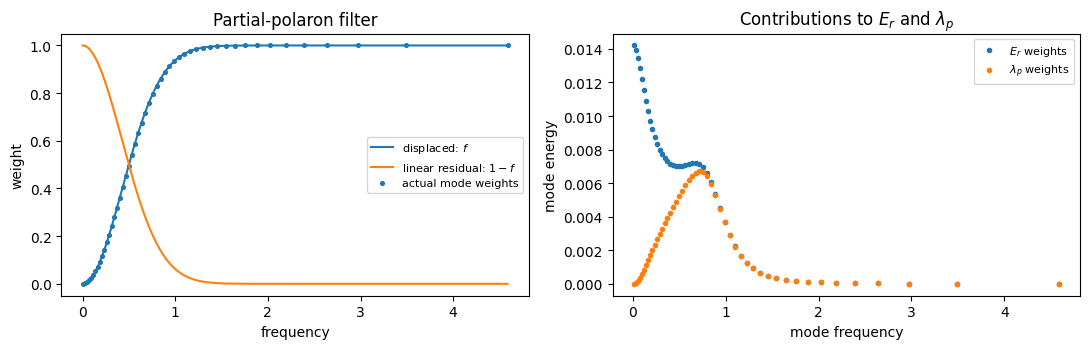

In [4]:
# f_q = 1 - exp[-(w/omega_h)^alpha] ;  lambda_p = 1/2 sum w^2 R^2 f (2-f) ;  B = exp(-phi(0)/2) ;  H~_S
fr = gp.make_frame(p, alpha, omega_h)
f, B, lp = fr.f, fr.B, fr.lambda_p
print(f'filter min/max: {f.min():.6f}, {f.max():.6f}')
print(f'B = {B:.9f};  lambda_p = {lp:.9f};  E_r - lambda_p = {Er - lp:.9f}')
print('H~_S =\n', fr.H_tilde.real, '\neigenvalues E =', fr.E)
assert np.isclose(B, np.exp(-0.5 * fr.phi(0.0)[0].real))
assert np.isclose(lp, 0.5 * np.sum(omega**2 * R**2 * f * (2 - f))) and 0 <= lp <= Er + 1e-10
assert np.allclose(fr.H_tilde, [[p.omega_DA, p.Gamma * B], [p.Gamma * B, Er - lp]])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
wplot = np.linspace(0, omega.max(), 400)
axes[0].plot(wplot, gp.polaron_filter(wplot, alpha, omega_h), label='displaced: $f$')
axes[0].plot(wplot, 1 - gp.polaron_filter(wplot, alpha, omega_h), label='linear residual: $1-f$')
axes[0].scatter(omega, f, s=7, label='actual mode weights')
axes[0].set(xlabel='frequency', ylabel='weight', title='Partial-polaron filter'); axes[0].legend(fontsize=8)
axes[1].plot(omega, 0.5 * omega**2 * R**2, 'o', ms=3, label='$E_r$ weights')
axes[1].plot(omega, 0.5 * omega**2 * R**2 * f * (2 - f), 'o', ms=3, label=r'$\lambda_p$ weights')
axes[1].set(xlabel='mode frequency', ylabel='mode energy', title=r'Contributions to $E_r$ and $\lambda_p$'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. From oscillator weights to the three primitive bath functions

**This is the central construction.** Let $n_q=(e^{\beta\omega_q}-1)^{-1}$, so $2n_q+1=\coth(\beta\omega_q/2)\equiv c_q$. With the residual-bath amplitudes

$$\xi_q=\sqrt{\omega_q/2}\,R_qf_q\quad(\text{displacement}),\qquad x_q=\sqrt{\omega_q^3/2}\,R_q(1-f_q)\quad(\text{residual linear}),$$

the code computes three complex mode sums:

$$\boxed{\phi(t)=\sum_q \xi_q^2\left[c_q\cos\omega_qt-i\sin\omega_qt\right]=\sum_q \frac{\omega_qR_q^2 f_q^2}{2}\left[c_q\cos\omega_qt-i\sin\omega_qt\right]}$$

$$\boxed{M(t)=\sum_q\xi_qx_q\left[\cos\omega_qt-i\,c_q\sin\omega_qt\right]=\sum_q\frac{\omega_q^2R_q^2f_q(1-f_q)}{2}\left[\cos\omega_qt-i\,c_q\sin\omega_qt\right]}$$

$$\boxed{C_X(t)=\sum_q x_q^2\left[c_q\cos\omega_qt-i\sin\omega_qt\right]=\sum_q\frac{\omega_q^3R_q^2(1-f_q)^2}{2}\left[c_q\cos\omega_qt-i\sin\omega_qt\right]}$$

$\phi$ comes from displacement–displacement (DD) contractions, $M$ from mixed displacement–linear (DX), and $C_X$ from linear–linear (XX). Note the **different placement of the thermal factor in $M$**: it multiplies the sine. These are *inputs* to the channel correlations, not the TCL generator.

phi          : max difference from independent sum = 2.781e-17
M (mixed)    : max difference from independent sum = 7.758e-18
C_X (linear) : max difference from independent sum = 7.152e-18


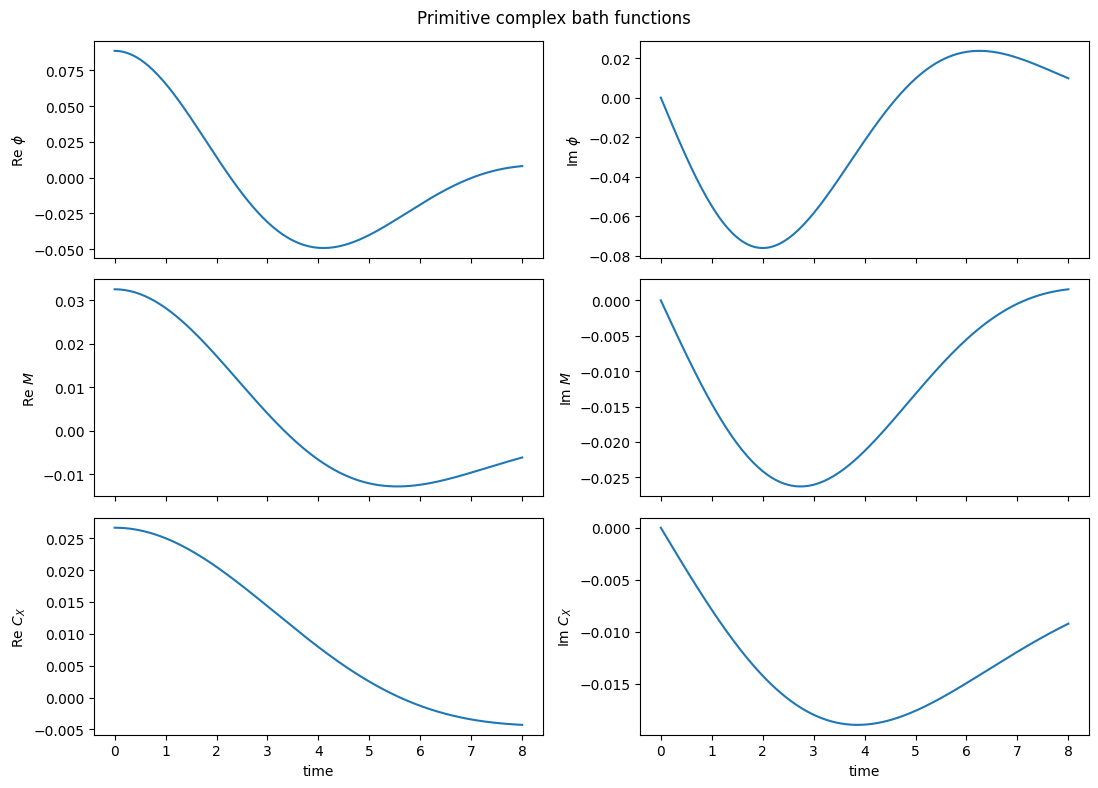

In [5]:
# phi = sum xi^2 [c cos - i sin] ;  M = sum xi x [cos - i c sin] ;  C_X = sum x^2 [c cos - i sin]
phi, mixed, linear = fr.phi(T), fr.mixed(T), fr.linear(T)
cth, xi, xq = fr.coth, fr.xi, fr.x
ph_ = np.outer(omega, T)
phi_manual    = (xi**2 * cth) @ np.cos(ph_) - 1j * (xi**2) @ np.sin(ph_)
mixed_manual  = (xi * xq) @ np.cos(ph_)     - 1j * (xi * xq * cth) @ np.sin(ph_)
linear_manual = (xq**2 * cth) @ np.cos(ph_) - 1j * (xq**2) @ np.sin(ph_)
for label, a_, b_ in [('phi', phi, phi_manual), ('M (mixed)', mixed, mixed_manual), ('C_X (linear)', linear, linear_manual)]:
    print(f'{label:13s}: max difference from independent sum = {np.max(abs(a_ - b_)):.3e}')
    assert np.allclose(a_, b_, atol=1e-12)
fig, ax = plt.subplots(3, 2, figsize=(11, 8), sharex=True)
for row, (lab, z) in enumerate([(r'\phi', phi), ('M', mixed), ('C_X', linear)]):
    ax[row, 0].plot(T, z.real); ax[row, 0].set_ylabel(f'Re ${lab}$')
    ax[row, 1].plot(T, z.imag); ax[row, 1].set_ylabel(f'Im ${lab}$')
ax[-1, 0].set_xlabel('time'); ax[-1, 1].set_xlabel('time'); fig.suptitle('Primitive complex bath functions')
plt.tight_layout(); plt.show()

## 5. Where does the pair phase $K_{jk,j'k'}(t)$ come from?

The indices $j,k$ label the **first hopping channel** $|j\rangle\langle k|$, and $j',k'$ the **second**. For site phases $\phi_j(t)$ with $\phi_D=0$, $\phi_A=\phi$,

$$\boxed{K_{jk,j'k'}(t)=\delta_{jj'}\phi_j+\delta_{kk'}\phi_k-\delta_{jk'}\phi_j-\delta_{kj'}\phi_k}\quad\Rightarrow\quad K_{DA,DA}=K_{AD,AD}=+\phi,\quad K_{DA,AD}=K_{AD,DA}=-\phi .$$

The hopping bath operators are $B_{DA}=\Gamma(D_--B)$ and $B_{AD}=\Gamma(D_+-B)$, with $D_s=\exp[s\sum_q\xi_q(b_q^\dagger-b_q)]$. Gaussian averaging gives $\langle D_s(t)D_{s'}(0)\rangle=B^2e^{-ss'\phi(t)}$, hence

$$\boxed{\mathcal C_{jk,j'k'}(t)=\widetilde J_{jk}\widetilde J_{j'k'}\left[e^{-K_{jk,j'k'}(t)}-1\right],\qquad \widetilde J_{DA}=\widetilde J_{AD}=\Gamma B.}$$

The "$-1$" comes from subtracting $\langle D_s\rangle=B$, which centres the fluctuations. The cell checks this closed form against the general multi-time moment engine of Part II, which knows nothing about $K_{jk,j'k'}$.

In [6]:
# C_{jk,j'k'}(t) = (Gamma B)^2 [exp(-K_{jk,j'k'}(t)) - 1],  K = +phi (same channel), -phi (opposite channel)
bm = gp.ResidualBath(fr)                       # exact Gaussian moments (Part II)
names = {2: 'DA', 3: 'AD'}; sgn = {(2, 2): +1, (3, 3): +1, (2, 3): -1, (3, 2): -1}
t_test = 1.7
for (a_, b_), s_ in sgn.items():
    closed = (p.Gamma * B)**2 * np.expm1(-s_ * fr.phi(t_test)[0])
    engine = bm.moment_at((a_, b_), (t_test, 0.0))
    print(f'C_{{{names[a_]},{names[b_]}}}({t_test}):  K = {"+" if s_ > 0 else "-"}phi   closed form {closed:.6e}   moment engine {engine:.6e}')
    assert abs(closed - engine) < 1e-12

C_{DA,DA}(1.7):  K = +phi   closed form -1.202719e-03+2.635268e-03j   moment engine -1.202719e-03+2.635268e-03j
C_{AD,AD}(1.7):  K = +phi   closed form -1.202719e-03+2.635268e-03j   moment engine -1.202719e-03+2.635268e-03j
C_{DA,AD}(1.7):  K = -phi   closed form 1.035048e-03-2.801813e-03j   moment engine 1.035048e-03-2.801813e-03j
C_{AD,DA}(1.7):  K = -phi   closed form 1.035048e-03-2.801813e-03j   moment engine 1.035048e-03-2.801813e-03j


## 6. How $\phi$, $M$ and $C_X$ form the *entire* channel tensor $\mathcal C(t)$

There are four stored channels `(DD, AA, DA, AD)`. The `DD` bath operator is identically zero, which leaves **three active channels** $AA$, $DA$, $AD$. With $\mathcal C_{ab}(t)=\langle B_a(t)B_b(0)\rangle$ and $\tilde a=\Gamma B$:

$$\boxed{\mathcal C(t)=\begin{pmatrix}
C_X&-\tilde aM&+\tilde aM\\
+\tilde aM&\tilde a^2(e^{-\phi}-1)&\tilde a^2(e^{+\phi}-1)\\
-\tilde aM&\tilde a^2(e^{+\phi}-1)&\tilde a^2(e^{-\phi}-1)
\end{pmatrix}}\qquad(\text{rows/columns } AA, DA, AD).$$

The top-left entry is linear–linear, the mixed entries are $\pm\tilde aM$ (from $\langle X(t)D_s(0)\rangle=sB\,M(t)$ and $\langle D_s(t)X(0)\rangle=-sB\,M(t)$), and the lower-right $2\times2$ block is hopping–hopping.

The **backward** tensor needed by TCL2 is $\mathcal C^-_{ba}(t)=\langle B_b(-t)B_a(0)\rangle=\mathcal C_{\bar a\bar b}(t)^*$ ($\bar a$ = adjoint channel: $\overline{DA}=AD$, $\overline{AA}=AA$). It is the same table with $\phi,M,C_X\to\phi^*,M^*,C_X^*$.

shape full tensor: (4, 4, 161)  active block: (3, 3, 161)
max |C - closed-form table| = 0.0
all 9 entries agree with the moment engine; C^- = conj(C_{abar bbar}) verified


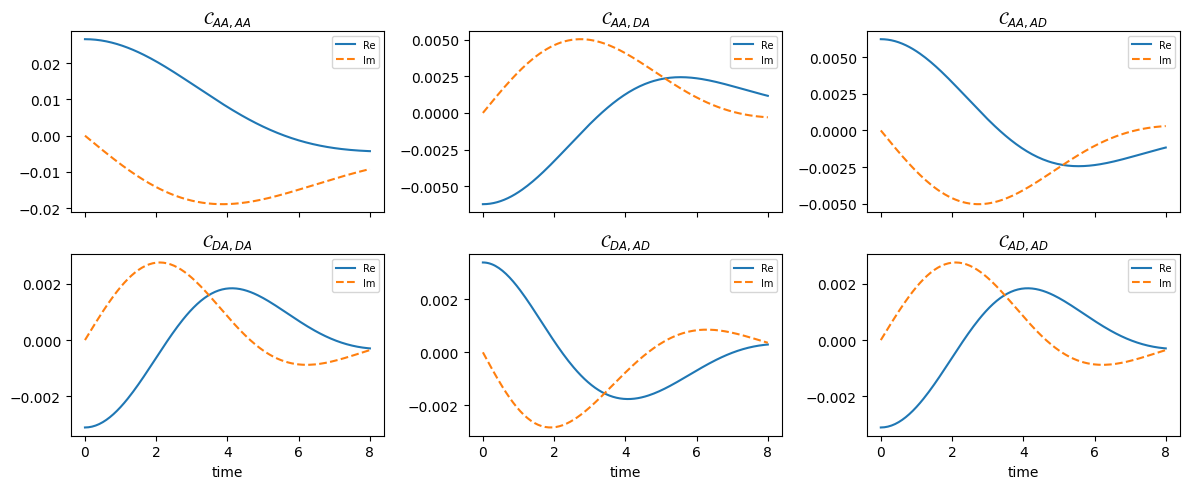

In [7]:
# C_ab(t) = <B_a(t) B_b(0)> (table above) ;  C^-_ba(t) = <B_b(-t) B_a(0)> = conj(C_{abar,bbar}(t))
C, Cm = gp.correlation_tensors(fr, T)
a_t = p.Gamma * B
manual = np.zeros((3, 3, len(T)), complex)
manual[0, 0] = linear
manual[0, 1], manual[0, 2] = -a_t * mixed, a_t * mixed
manual[1, 0], manual[2, 0] = a_t * mixed, -a_t * mixed
manual[1, 1] = manual[2, 2] = a_t**2 * np.expm1(-phi)
manual[1, 2] = manual[2, 1] = a_t**2 * np.expm1(phi)
print('shape full tensor:', C.shape, ' active block:', C[1:, 1:].shape)
print('max |C - closed-form table| =', np.max(np.abs(C[1:, 1:] - manual)))
assert np.allclose(C[1:, 1:], manual) and np.allclose(C[0], 0) and np.allclose(C[:, 0], 0)
# every entry against the moment engine at one time, and the backward relation
adj = {1: 1, 2: 3, 3: 2}; it = 37
for a_ in (1, 2, 3):
    for b_ in (1, 2, 3):
        assert abs(bm.moment_at((a_, b_), (T[it], 0.0)) - C[a_, b_, it]) < 1e-12
        assert np.allclose(Cm[b_, a_], np.conj(C[adj[a_], adj[b_]]))
print('all 9 entries agree with the moment engine; C^- = conj(C_{abar bbar}) verified')
fig, axes = plt.subplots(2, 3, figsize=(12, 5), sharex=True)
for ii, (label, xy) in enumerate([('AA,AA', (1, 1)), ('AA,DA', (1, 2)), ('AA,AD', (1, 3)), ('DA,DA', (2, 2)), ('DA,AD', (2, 3)), ('AD,AD', (3, 3))]):
    r_, c_ = divmod(ii, 3); z = C[xy]
    axes[r_, c_].plot(T, z.real, label='Re'); axes[r_, c_].plot(T, z.imag, '--', label='Im')
    axes[r_, c_].set_title(r'$\mathcal{C}_{%s}$' % label); axes[r_, c_].legend(fontsize=7)
for a0 in axes[-1]: a0.set_xlabel('time')
plt.tight_layout(); plt.show()

## 7. Why $\mathcal C$ is *not* directly $\mathcal K_2$: insert system evolution and integrate

The site operators $S_{jk}=|j\rangle\langle k|$ are transformed to the eigenbasis of $\widetilde H_S$: $S_a^{(e)}=U_e^\dagger S_aU_e$. The **finite-time rate tensors** are ($\Delta_{mn}=E_m-E_n$)

$$W^f_{ab,mn}(t)=\int_0^t ds\,\mathcal C_{ab}(s)\,e^{-i\Delta_{mn}s},\qquad W^b_{ab,mn}(t)=\int_0^t ds\,\mathcal C^-_{ab}(s)\,e^{-i\Delta_{mn}s}.$$

They are evaluated by cumulative trapezoid on the propagation grid (error $O(dt^2)$). A Hadamard (elementwise) product with $S_b^{(e)}$ gives

$$\Lambda_a(t)=\sum_bW^f_{ab}(t)\circ S_b=\int_0^t ds\sum_b\mathcal C_{ab}(s)\,S_b(-s),\qquad \bar\Lambda_a(t)=\sum_bW^b_{ba}(t)\circ S_b,$$

because $[S_b(-s)]_{mn}=[e^{-i\widetilde H_Ss}S_be^{i\widetilde H_Ss}]_{mn}=e^{-i\Delta_{mn}s}[S_b]_{mn}$.

In [8]:
# Wf_{ab,mn}(t) = int_0^t ds C_ab(s) exp(-i (E_m-E_n) s)   (cumulative trapezoid)
from scipy.integrate import trapezoid
tc = gp.TCL2(fr, T)                    # C, Cm, Wf, Wb, L on the grid T
E, U, S = fr.E, fr.U, fr.S
print('energy eigenvalues:', E)
print('arrays: C', tc.C.shape, ' Wf', tc.Wf.shape, '[t,a,b,m,n]   L', tc.L.shape)
assert np.allclose(tc.Wf[0], 0)
idx = len(T) // 2; aa, bb, m, n = 2, 3, 0, 1
check = trapezoid(C[aa, bb, :idx+1] * np.exp(-1j * (E[m] - E[n]) * T[:idx+1]), x=T[:idx+1])
print('Wf[t=%.2f, DA, AD, 0, 1] = %s ;  independent trapezoid = %s' % (T[idx], tc.Wf[idx, aa, bb, m, n], check))
assert np.allclose(check, tc.Wf[idx, aa, bb, m, n], atol=1e-12)

energy eigenvalues: [-0.129167  0.28344 ]
arrays: C (4, 4, 161)  Wf (161, 4, 4, 2, 2) [t,a,b,m,n]   L (161, 4, 4)
Wf[t=4.00, DA, AD, 0, 1] = (0.009214083154836171-0.005351151357176209j) ;  independent trapezoid = (0.009214083154836166-0.005351151357176207j)


## 8. Construct $\mathcal L_2(t)$, then propagate the TCL2 state

In the Schrödinger picture of the transformed system,

$$\boxed{\mathcal L_2(t)\rho=-i[\widetilde H_S,\rho]+\sum_a\Big(\Lambda_a\rho S_a-S_a\Lambda_a\rho-\rho\bar\Lambda_aS_a+S_a\rho\bar\Lambda_a\Big)}$$

Each term $X\rho Y$ becomes $(Y^T\otimes X)\operatorname{vec}\rho$, which gives an array of $4\times4$ matrices. Trace preservation means $(1,0,0,1)\,\mathcal L_2=0$. Propagation uses the exponential midpoint rule

$$\operatorname{vec}\rho_{k+1}=\exp\!\Big[\tfrac{\Delta t}{2}\big(\mathcal L(t_k)+\mathcal L(t_{k+1})\big)\Big]\operatorname{vec}\rho_k,\qquad\rho(0)=U_e^\dagger|D\rangle\langle D|U_e .$$

Populations are the same in the lab and the transformed frame, because the transformation is conditioned on $|A\rangle\langle A|$.

L2(t) shape: (161, 4, 4)   max trace-preservation residual: 2.7809732887839817e-17
initial populations: 1.0000000000000004 2.7755575615628914e-17    final populations: 0.3098869153040664 0.6901130846959348


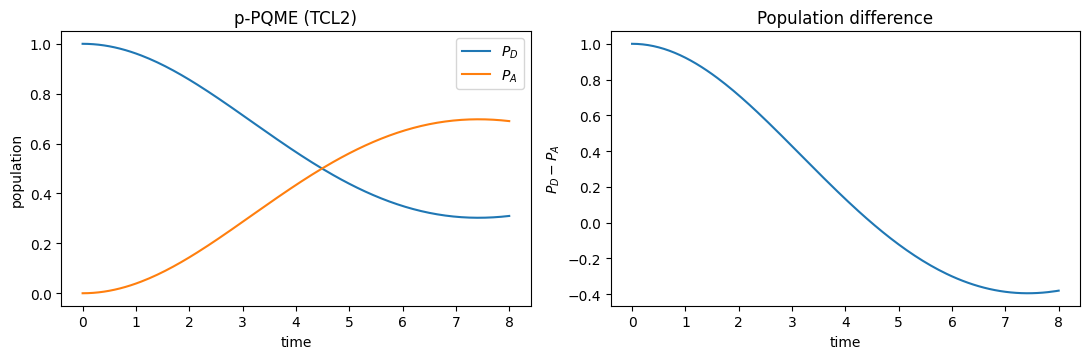

In [9]:
# L2(t) rho = -i[H~,rho] + sum_a (Lam_a rho S_a - S_a Lam_a rho - rho Lam'_a S_a + S_a rho Lam'_a) ;  midpoint expm
L2 = tc.L
trace_residual = np.max(np.abs(np.einsum('i,tij->tj', liouville.TRACE_ROW, L2)))
print('L2(t) shape:', L2.shape, '  max trace-preservation residual:', trace_residual)
assert trace_residual < 1e-10
rho0 = gp.rho0_donor(fr)
rho_e = gp.propagate(L2, T, rho0)
rho_site = gp.to_site(fr, rho_e)
pd_, pa_ = rho_site[:, 0, 0].real, rho_site[:, 1, 1].real
print('initial populations:', pd_[0], pa_[0], '   final populations:', pd_[-1], pa_[-1])
assert np.allclose(pd_ + pa_, 1, atol=5e-9)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
axes[0].plot(T, pd_, label='$P_D$'); axes[0].plot(T, pa_, label='$P_A$'); axes[0].set(xlabel='time', ylabel='population', title='p-PQME (TCL2)'); axes[0].legend()
axes[1].plot(T, pd_ - pa_); axes[1].set(xlabel='time', ylabel='$P_D-P_A$', title='Population difference')
plt.tight_layout(); plt.show()

## 9. Three limiting-case checks you should always perform

1. **Laboratory frame**, $\omega_h\to\infty$: $f_q\to0$, so $\phi,M\to0$, $B\to1$, $\lambda_p\to0$, and $C_X(t)\to C(t)=\sum_q\frac{\omega_q^3R_q^2}{2}[c_q\cos\omega_qt-i\sin\omega_qt]$ (the original bath).
2. **Full polaron**, $\omega_h\to0$: $f_q\to1$, so $C_X\to0$, $M\to0$ and $\lambda_p\to E_r$. Only the hopping fluctuations remain.
3. **Reorganisation energy**: $\sum_q\omega_q^2R_q^2/2=2\Omega^2y_0^2$ for every filter.

In [10]:
# lab: f->0 => C_X -> C(t), phi, M -> 0 ;  full polaron: f->1 => C_X, M -> 0, lambda_p -> E_r
lt = np.array([0.0, 0.7, 2.0])
f_lab, f_full = gp.make_frame(p, alpha, 1e6), gp.make_frame(p, alpha, 1e-6)
C_orig = bath.lab_correlation(modes, p.beta, lt)
print('lab limit:   max|phi| = %.1e  max|M| = %.1e  max|C_X - C| = %.1e  B-1 = %.1e' % (
    np.max(abs(f_lab.phi(lt))), np.max(abs(f_lab.mixed(lt))), np.max(abs(f_lab.linear(lt) - C_orig)), f_lab.B - 1))
print('full limit:  max|M| = %.1e  max|C_X| = %.1e  lambda_p - E_r = %.1e' % (
    np.max(abs(f_full.mixed(lt))), np.max(abs(f_full.linear(lt))), f_full.lambda_p - Er))
assert np.max(abs(f_lab.linear(lt) - C_orig)) < 1e-10 and np.max(abs(f_full.linear(lt))) < 1e-10
assert np.isclose(f_full.lambda_p, Er, atol=1e-9)

lab limit:   max|phi| = 6.0e-26  max|M| = 7.0e-14  max|C_X - C| = 1.2e-13  B-1 = 0.0e+00
full limit:  max|M| = 0.0e+00  max|C_X| = 0.0e+00  lambda_p - E_r = 0.0e+00


# Part II: from the bath correlation functions to $\mathcal K_2$, $\mathcal K_3$, $\mathcal K_4$ and $r_4$

## 10. The interaction picture and the second Liouville moment $\mathcal M_2$

Work in the interaction picture of $\widetilde H_S$. The residual interaction is $\widetilde H_I(t)=\sum_aS_a(t)\otimes B_a(t)$ with

$$[S_a(t)]_{mn}=e^{i(E_m-E_n)t}[S_a]_{mn},\qquad \mathcal L(t)\,\cdot=-i[\widetilde H_I(t),\cdot\,] .$$

With the projector $\mathcal P\rho_{\rm tot}=\operatorname{Tr}_B(\rho_{\rm tot})\otimes\rho_B$ and $\langle B_a\rangle=0$ (so $\mathcal P\mathcal L\mathcal P=0$), the TCL expansion is built from the **Liouville moments**

$$\mathcal M_n(t_0,\dots,t_{n-1})=\mathcal P\mathcal L(t_0)\mathcal L(t_1)\cdots\mathcal L(t_{n-1})\mathcal P,\qquad t_0\ge t_1\ge\dots$$

Expand every commutator into a left (L) and right (R) action. The bath operators end up as $\operatorname{Tr}_B[\text{L-ops}\,\rho_B\,\text{R-ops}]=\langle\text{R-ops}\;\text{L-ops}\rangle$. For $n=2$, $(t_0,t_1)=(t,t_1)$ and $\tau=t-t_1$, the four branch combinations give

| branches | coefficient | bath factor | system action |
|---|---|---|---|
| L L | $(-i)^2$ | $\langle B_a(t)B_b(t_1)\rangle=\mathcal C_{ab}(\tau)$ | $S_a(t)S_b(t_1)\rho$ |
| R L | $(+i)(-i)$ | $\langle B_a(t)B_b(t_1)\rangle=\mathcal C_{ab}(\tau)$ | $S_b(t_1)\rho\,S_a(t)$ |
| L R | $(-i)(+i)$ | $\langle B_b(t_1)B_a(t)\rangle=\mathcal C^-_{ba}(\tau)$ | $S_a(t)\rho\,S_b(t_1)$ |
| R R | $(+i)^2$ | $\langle B_b(t_1)B_a(t)\rangle=\mathcal C^-_{ba}(\tau)$ | $\rho\,S_b(t_1)S_a(t)$ |

so that

$$\boxed{\mathcal M_2(t,t_1)\rho=\sum_{ab}\Big\{\mathcal C_{ab}(\tau)\big[S_b(t_1)\rho S_a(t)-S_a(t)S_b(t_1)\rho\big]+\mathcal C^-_{ba}(\tau)\big[S_a(t)\rho S_b(t_1)-\rho S_b(t_1)S_a(t)\big]\Big\}}$$

**This is how the bath correlation function enters $\mathcal K_2$:** only the two-time tensors $\mathcal C$ and $\mathcal C^-$ of Section 6 appear, multiplied by interaction-picture system operators. The cell builds $\mathcal M_2$ from this formula and compares it with the general $n$-th order engine (`MomentEngine.liouville_moment`), which sums all $3^n\times2^n$ channel/branch terms with exact bath moments.

In [11]:
# M2(t,t1) rho = sum_ab { C_ab(tau)[S_b(t1) rho S_a(t) - S_a(t) S_b(t1) rho] + C^-_ba(tau)[S_a(t) rho S_b(t1) - rho S_b(t1) S_a(t)] }
from goa_pqme.liouville import sup
eng = gp.MomentEngine(fr)
def S_int(a, t):                                   # [S_a(t)]_mn = e^{i(E_m - E_n)t} [S_a]_mn
    return np.exp(1j * (E[:, None] - E[None, :]) * t) * S[a]
def X(Lop, Rop):                                   # superoperator of rho -> Lop rho Rop  (= Rop^T kron Lop)
    return sup(Lop[None], Rop[None])[0]
I2 = np.eye(2)
for (t_, t1_) in [(3.0, 1.2), (6.5, 0.4)]:
    tau = t_ - t1_
    Ct, Cmt = gp.correlation_tensors(fr, [tau])
    M2_formula = np.zeros((4, 4), complex)
    for a_ in (1, 2, 3):
        for b_ in (1, 2, 3):
            Sa, Sb = S_int(a_, t_), S_int(b_, t1_)
            M2_formula += Ct[a_, b_, 0] * (X(Sb, Sa) - X(Sa @ Sb, I2)) + Cmt[b_, a_, 0] * (X(Sa, Sb) - X(I2, Sb @ Sa))
    M2_engine = eng.liouville_moment(np.array([[t_, t1_]]))[0]
    print(f'(t, t1) = ({t_}, {t1_}):  ||M2|| = {np.linalg.norm(M2_engine):.6f}   max|formula - engine| = {np.max(abs(M2_formula - M2_engine)):.2e}')
    assert np.allclose(M2_formula, M2_engine, atol=1e-13)

(t, t1) = (3.0, 1.2):  ||M2|| = 0.051682   max|formula - engine| = 3.12e-17
(t, t1) = (6.5, 0.4):  ||M2|| = 0.026534   max|formula - engine| = 2.83e-17


## 11. $\mathcal K_2(t)=\int_0^t dt_1\,\mathcal M_2(t,t_1)$ is exactly the TCL2 dissipator

$$\boxed{\mathcal K_2(t)=\int_0^t dt_1\,\mathcal M_2(t,t_1)}$$

Substitute $t_1=t-s$ and use $S_b(t-s)=e^{i\widetilde H_St}\,S_b(-s)\,e^{-i\widetilde H_St}$. The $s$-integral of $\mathcal C_{ab}(s)S_b(-s)$ is exactly $\Lambda_a(t)$ of Section 7, and that of $\mathcal C^-_{ba}(s)S_b(-s)$ is $\bar\Lambda_a(t)$. Hence

$$\mathcal K_2(t)=\mathcal P(t)^{-1}\big[\mathcal L_2(t)-\mathcal L_H\big]\mathcal P(t),\qquad \mathcal L_H=-i[\widetilde H_S,\cdot\,],\qquad \mathcal P(t)=\operatorname{diag}\big(e^{-i\Delta_\mu t}\big),$$

where $\Delta_\mu=E_{m_\mu}-E_{n_\mu}$ for Liouville index $\mu=m_\mu+2n_\mu$. In words: *the TCL2 dissipator is $\mathcal K_2$ seen in the Schrödinger picture.*

Numerically the code evaluates the $t_1$ integral with composite Gauss–Legendre quadrature (`nq` points on panels of width $\le h$). The TCL2 code uses a trapezoid rule on the $dt$ grid instead, so the two agree up to $O(dt^2)$.

max relative difference K2 (Gauss-Legendre) vs TCL2 dissipator (trapezoid, dt=0.05): 4.10e-05


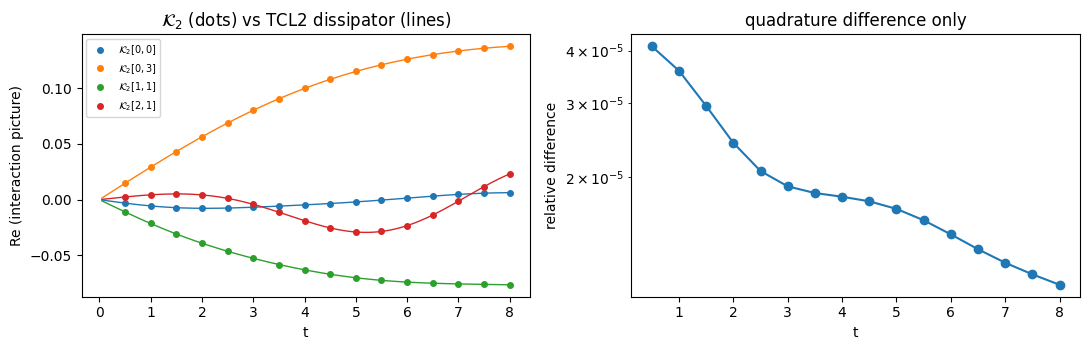

In [12]:
# K2(t) = int_0^t dt1 M2(t,t1)  ==  P(t)^-1 [L2(t) - L_H] P(t)
from goa_pqme.liouville import commutator_generator, to_interaction
times = np.arange(0.5, tmax + 1e-9, 0.5)
K2_direct = np.array([eng.K(t_, 6, 1.0, orders=(2,))[2] for t_ in times])
iT = np.rint(times / dt).astype(int)
D_int = to_interaction(tc.L[iT] - commutator_generator(E), E, times)
rel = np.linalg.norm(K2_direct - D_int, axis=(1, 2)) / np.linalg.norm(K2_direct, axis=(1, 2))
print('max relative difference K2 (Gauss-Legendre) vs TCL2 dissipator (trapezoid, dt=%.2f): %.2e' % (dt, rel.max()))
assert rel.max() < 1e-3
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for (i_, j_), c_ in [((0, 0), 'C0'), ((0, 3), 'C1'), ((1, 1), 'C2'), ((2, 1), 'C3')]:
    ax[0].plot(times, K2_direct[:, i_, j_].real, 'o', color=c_, ms=4, label=r'$\mathcal{K}_2[%d,%d]$' % (i_, j_))
    ax[0].plot(T[1:], to_interaction(tc.L[1:] - commutator_generator(E), E, T[1:])[:, i_, j_].real, '-', color=c_, lw=1)
ax[0].set(xlabel='t', ylabel='Re (interaction picture)', title=r'$\mathcal{K}_2$ (dots) vs TCL2 dissipator (lines)'); ax[0].legend(fontsize=7)
ax[1].semilogy(times, rel, 'o-'); ax[1].set(xlabel='t', ylabel='relative difference', title='quadrature difference only')
plt.tight_layout(); plt.show()

## 12. Beyond two times: exact multi-time moments of the residual bath

$\mathcal K_3$ and $\mathcal K_4$ need $\langle B_{a_1}(t_1)B_{a_2}(t_2)B_{a_3}(t_3)\rangle$ and four-time moments. The underlying bath is harmonic and Gaussian, but the hopping operators $B_{DA},B_{AD}=\Gamma(D_\mp-B)$ are *exponentials* of bath coordinates, so they are **not** Gaussian. Their odd moments do not vanish, which is why $\mathcal K_3\neq0$.

**Method.** Expand every hopping factor, $\Gamma(D_s-B)\to\Gamma D_s$ or $-\Gamma B$. Each remaining ordered product of exponentials and linear operators is evaluated exactly using the Baker–Campbell–Hausdorff formula and Wick's theorem:

$$\Big\langle\prod_i e^{u_ib^\dagger+v_ib}\Big\rangle=\exp\Big[\sum_{i<j}\tfrac12(v_iu_j-u_iv_j)+\big(n+\tfrac12\big)\textstyle\sum_iu_i\sum_jv_j\Big]\quad(\text{per mode}).$$

For hopping operators alone this gives the closed form ($s=-1$ for $DA$, $+1$ for $AD$; $\phi_{ij}=\phi(t_i-t_j)$, operator order $1,2,3$):

$$\boxed{\big\langle B_{a_1}(t_1)B_{a_2}(t_2)B_{a_3}(t_3)\big\rangle_{\rm hop}=\Gamma^3B^3\Big[e^{-s_1s_2\phi_{12}-s_1s_3\phi_{13}-s_2s_3\phi_{23}}-e^{-s_1s_2\phi_{12}}-e^{-s_1s_3\phi_{13}}-e^{-s_2s_3\phi_{23}}+2\Big]}$$

which follows from $\langle D_{s_i}\rangle=B$, $\langle D_{s_i}D_{s_j}\rangle=B^2e^{-s_is_j\phi_{ij}}$ and $\langle D_1D_2D_3\rangle=B^3e^{-\sum_{i<j}s_is_j\phi_{ij}}$. By contrast, a purely linear (Gaussian) moment such as $\langle X(t_1)X(t_2)X(t_3)\rangle$ vanishes identically. Moments that contain linear operators $X$ are handled by summing over partial pairings: each X is either contracted with another X (pair function from $C_X$) or with the exponentials (a linear term built from $M$).

In [13]:
# <B_a1 B_a2 B_a3>_hop = (Gamma B)^3 [e^{-s1s2 phi12 - s1s3 phi13 - s2s3 phi23} - e^{-s1s2 phi12} - e^{-s1s3 phi13} - e^{-s2s3 phi23} + 2]
t1_, t2_, t3_ = 2.5, 1.4, 0.3
sgn_of = {2: -1.0, 3: +1.0}
phi_at = lambda x: fr.phi([x])[0]
for ch in [(2, 3, 2), (3, 3, 2), (2, 2, 2)]:
    s1, s2, s3 = (sgn_of[c] for c in ch)
    e12, e13, e23 = np.exp(-s1*s2*phi_at(t1_-t2_)), np.exp(-s1*s3*phi_at(t1_-t3_)), np.exp(-s2*s3*phi_at(t2_-t3_))
    closed = (p.Gamma * B)**3 * (e12 * e13 * e23 - e12 - e13 - e23 + 2)
    engine = bm.moment_at(ch, (t1_, t2_, t3_))
    print('<B_%s B_%s B_%s>:' % tuple(names[c] for c in ch), f'closed form {closed:.6e}   engine {engine:.6e}')
    assert abs(closed - engine) < 1e-13
xxx = bm.moment_at((1, 1, 1), (t1_, t2_, t3_))
xx  = bm.moment_at((1, 1), (t1_, t2_))
print(f'Gaussian check: |<X X X>| = {abs(xxx):.1e} (must be 0);   <X X> = {xx:.6e} = C_X(t1-t2) = {fr.linear([t1_ - t2_])[0]:.6e}')
assert abs(xxx) < 1e-15 and abs(xx - fr.linear([t1_ - t2_])[0]) < 1e-13
print('mixed 3-point example <X D_- D_+> moment: %.6e' % abs(bm.moment_at((1, 2, 3), (t1_, t2_, t3_))))

<B_DA B_AD B_DA>: closed form 6.298814e-05+1.674179e-05j   engine 6.298814e-05+1.674179e-05j
<B_AD B_AD B_DA>: closed form -1.890394e-06+5.051699e-05j   engine -1.890394e-06+5.051699e-05j
<B_DA B_DA B_DA>: closed form -4.445790e-05-1.159241e-04j   engine -4.445790e-05-1.159241e-04j
Gaussian check: |<X X X>| = 0.0e+00 (must be 0);   <X X> = 2.466403e-02-8.603599e-03j = C_X(t1-t2) = 2.466403e-02-8.603599e-03j
mixed 3-point example <X D_- D_+> moment: 5.071582e-05


## 13. $\mathcal K_3$: the third-order generator and the nested quadrature

For $\mathcal P\mathcal L\mathcal P=0$ the third-order ordered cumulant is just the third moment:

$$\boxed{\mathcal K_3(t)=\int_0^t dt_1\int_0^{t_1}dt_2\;\mathcal M_3(t,t_1,t_2)}$$

where $\mathcal M_3$ is a sum over $3^3$ channel assignments $\times\,2^3$ L/R branches, each weighted by an exact three-time bath moment (Section 12).

**Quadrature.** The time-ordered simplex $t>t_1>\dots>t_d>0$ is covered by *nested* composite Gauss–Legendre rules. Each inner interval $[0,t_k]$ is split into $\lceil t_k/h\rceil$ panels with `nq` nodes, and the weights multiply. A built-in check is that the weights integrate 1 exactly over the simplex:

$$\sum_{\rm nodes}w=\int_0^t\!dt_1\!\int_0^{t_1}\!dt_2\cdots=\frac{t^d}{d!}.$$

K2:     8 time tuples   sum w = 6.0000000000   t^d/d! = 6.0000000000
K3:    48 time tuples   sum w = 18.0000000000   t^d/d! = 18.0000000000
K4:   232 time tuples   sum w = 36.0000000000   t^d/d! = 36.0000000000


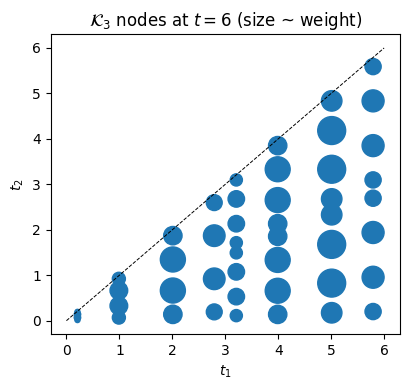

In [14]:
# nested Gauss-Legendre on t > t1 > ... > t_d > 0 :  sum of weights = t^d / d!
t_q, nq, h = 6.0, 4, 3.0
for d, name in ((1, 'K2'), (2, 'K3'), (3, 'K4')):
    Tn, Wn = gp.nested_nodes(t_q, d, nq, h)
    print(f'{name}: {Tn.shape[0]:5d} time tuples   sum w = {Wn.sum():.10f}   t^d/d! = {t_q**d / math.factorial(d):.10f}')
    assert np.isclose(Wn.sum(), t_q**d / math.factorial(d))
Tn, Wn = gp.nested_nodes(t_q, 2, nq, h)
fig, ax = plt.subplots(figsize=(4.2, 4))
ax.scatter(Tn[:, 1], Tn[:, 2], s=4 + 400 * Wn / Wn.max()); ax.plot([0, t_q], [0, t_q], 'k--', lw=0.7)
ax.set(xlabel='$t_1$', ylabel='$t_2$', title=r'$\mathcal{K}_3$ nodes at $t=%g$ (size ~ weight)' % t_q)
plt.tight_layout(); plt.show()

### 13b. Evaluate $\mathcal K_2,\mathcal K_3,\mathcal K_4$ at sparse time nodes

$\mathcal K_n(t)$ is smooth but expensive (about $(nq\,\lceil t/h\rceil)^{n-1}$ tuples per time), so it is computed only at nodes $t_k=k\,\Delta t_{\rm node}$, with $\mathcal K_n(0)=0$. Each $\mathcal K_n$ must be trace preserving, $(1,0,0,1)\,\mathcal K_n=0$, because every term is a sum of commutators.

nodes: [0. 1. 2. 3. 4. 5. 6. 7. 8.]   (2.1 s)
K2: shape (9, 4, 4),  max trace residual 1.4e-17,  ||K2(tmax)|| = 2.8312e-01
K3: shape (9, 4, 4),  max trace residual 8.7e-19,  ||K3(tmax)|| = 9.6349e-03
K4: shape (9, 4, 4),  max trace residual 7.0e-18,  ||K4(tmax)|| = 6.3351e-02


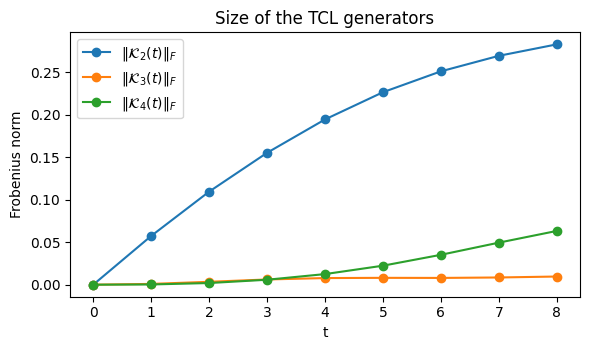

In [15]:
# K_n(t_k) at t_k = k * node_dt (interaction picture) ;  trace preservation (1,0,0,1) K_n = 0
NODE_DT, NQ, PANEL = 1.0, 4, 3.0
import time as _time
_t0 = _time.time()
kn = gp.K_nodes(fr, tmax, NODE_DT, NQ, PANEL)            # orders 2, 3, 4
print('nodes:', kn.t, '  (%.1f s)' % (_time.time() - _t0))
for n_ in (2, 3, 4):
    tr = np.max(np.abs(np.einsum('i,tij->tj', liouville.TRACE_ROW, kn.K[n_])))
    print(f'K{n_}: shape {kn.K[n_].shape},  max trace residual {tr:.1e},  ||K{n_}(tmax)|| = {np.linalg.norm(kn.K[n_][-1]):.4e}')
    assert tr < 1e-12
fig, ax = plt.subplots(figsize=(6, 3.6))
for n_ in (2, 3, 4):
    ax.plot(kn.t, np.linalg.norm(kn.K[n_], axis=(1, 2)), 'o-', label=r'$\|\mathcal{K}_%d(t)\|_F$' % n_)
ax.set(xlabel='t', ylabel='Frobenius norm', title='Size of the TCL generators'); ax.legend()
plt.tight_layout(); plt.show()

## 14. $\mathcal K_4$: the ordered (partial) cumulant

The fourth moment $\mathcal M_4$ contains *disconnected* pieces, products of two second-order moments, which grow like $t^2$ and would double-count $\mathcal K_2$ iterated in time. The TCL generator keeps only the ordered cumulant:

$$\boxed{\mathcal K_4(t)=\int_0^t\!dt_1\!\int_0^{t_1}\!dt_2\!\int_0^{t_2}\!dt_3\Big[\mathcal M_4(t,t_1,t_2,t_3)-\mathcal M_2(t,t_1)\mathcal M_2(t_2,t_3)-\mathcal M_2(t,t_2)\mathcal M_2(t_1,t_3)-\mathcal M_2(t,t_3)\mathcal M_2(t_1,t_2)\Big]}$$

The products are $4\times4$ matrix products of superoperators, evaluated on the same quadrature tuples. The cell shows that the two integrals are each much larger than their difference: the cumulant is a strong cancellation.

In [16]:
# K4 = int [M4 - M2(t,t1)M2(t2,t3) - M2(t,t2)M2(t1,t3) - M2(t,t3)M2(t1,t2)]
t4 = 4.0
Tn, Wn = gp.nested_nodes(t4, 3, NQ, PANEL)
M4 = eng.liouville_moment(Tn)
Pm = {pq: eng.liouville_moment(Tn[:, list(pq)]) for pq in tcl_higher.PAIRS_K4}
disconnected = Pm[(0, 1)] @ Pm[(2, 3)] + Pm[(0, 2)] @ Pm[(1, 3)] + Pm[(0, 3)] @ Pm[(1, 2)]
I_M4, I_dis = np.einsum('n,nij->ij', Wn, M4), np.einsum('n,nij->ij', Wn, disconnected)
K4_manual = I_M4 - I_dis
print(f't = {t4}:  ||int M4|| = {np.linalg.norm(I_M4):.4e}   ||int (pair products)|| = {np.linalg.norm(I_dis):.4e}   ||K4|| = {np.linalg.norm(K4_manual):.4e}')
assert np.allclose(K4_manual, eng.K(t4, NQ, PANEL, orders=(4,))[4])
print('K4 from the explicit cumulant equals MomentEngine.K  ->  OK')

t = 4.0:  ||int M4|| = 4.2306e-02   ||int (pair products)|| = 4.6572e-02   ||K4|| = 1.2504e-02


K4 from the explicit cumulant equals MomentEngine.K  ->  OK


### 14b. Which vertices drive $\mathcal K_3$ and $\mathcal K_4$? Channel resolution by $n_X$

Every term of $\mathcal M_n$ has a channel assignment $(a_1,\dots,a_n)$. Group the terms by the number of **linear** vertices, $n_X=\#\{k:a_k=AA\}$:

$$\mathcal K_n=\sum_{n_X=0}^{n}\mathcal K_n^{(n_X)},\qquad n_X=0:\ \text{hopping only},\qquad n_X=n:\ \text{linear only}.$$

For $\mathcal K_4$ the subtracted products are split consistently, according to the assignment of each factor. Two structural facts follow:

* $\mathcal K_3^{(3)}=0$: a purely linear three-point moment $\langle XXX\rangle$ is an odd Gaussian moment and vanishes. All of $\mathcal K_3$ comes from the non-Gaussian hopping operators.
* $\mathcal K_4^{(4)}\neq0$ in general, even though $X$ is Gaussian. The *bath* fourth cumulant vanishes, but the TCL4 ordered cumulant subtracts products of **superoperators** $\mathcal M_2(t,t_2)\mathcal M_2(t_1,t_3)$, etc. Their time ordering differs from the Wick pairing inside $\mathcal M_4$, and since the system operators do not commute the difference survives. This is the familiar non-zero TCL4 of the linearly coupled spin–boson model.

In [17]:
# K_n = sum_{nX} K_n^(nX) ;  Gaussian X => K3^(3) = 0  (but K4^(4) != 0: superoperator ordering)
res_c = eng.K(t4, NQ, PANEL, resolve=True)
tot_c = eng.K(t4, NQ, PANEL)
print('t = %g    ||K_n^(nX)||_F   (nX = number of linear AA vertices)' % t4)
for n_ in (2, 3, 4):
    print(f'  K{n_}: ' + '  '.join(f'nX={c}: {np.linalg.norm(res_c[n_][c]):.3e}' for c in range(n_ + 1)),
          f'  | sum - total = {np.max(abs(res_c[n_].sum(0) - tot_c[n_])):.1e}')
    assert np.allclose(res_c[n_].sum(0), tot_c[n_])
assert np.linalg.norm(res_c[3][3]) < 1e-12 * np.linalg.norm(tot_c[3]) + 1e-15
print('K3^(3) = 0 (odd Gaussian moment);  K4^(4)/||K4|| = %.2f  (non-zero: ordered cumulant of non-commuting superoperators)'
      % (np.linalg.norm(res_c[4][4]) / np.linalg.norm(tot_c[4])))

t = 4    ||K_n^(nX)||_F   (nX = number of linear AA vertices)
  K2: nX=0: 3.052e-02  nX=1: 8.186e-02  nX=2: 1.223e-01   | sum - total = 1.4e-17
  K3: nX=0: 1.104e-03  nX=1: 3.299e-03  nX=2: 5.391e-03  nX=3: 0.000e+00   | sum - total = 8.7e-19
  K4: nX=0: 5.487e-04  nX=1: 2.204e-03  nX=2: 5.550e-03  nX=3: 8.344e-03  nX=4: 4.378e-03   | sum - total = 2.6e-18
K3^(3) = 0 (odd Gaussian moment);  K4^(4)/||K4|| = 0.35  (non-zero: ordered cumulant of non-commuting superoperators)


## 15. The generator-size ratios $r_3$ and $r_4$

To judge whether the TCL series is converging in a given frame, compare the sizes of the generators over the time window (root mean square over the non-zero nodes $t_k$, Frobenius norm):

$$\boxed{r_n=\frac{\Big[\frac1{N_{\rm nodes}}\sum_{k\ge1}\|\mathcal K_n(t_k)\|_F^2\Big]^{1/2}}{\Big[\frac1{N_{\rm nodes}}\sum_{k\ge1}\|\mathcal K_2(t_k)\|_F^2\Big]^{1/2}},\qquad n=3,4 .}$$

Small $r_4$ means the fourth-order correction is a small perturbation of TCL2. The frame-independence analysis keeps frames with $r_3,r_4<0.5$ as "plausibly convergent", and $r_4$ is the control parameter studied in `mechanism_tests.py`.

$r_4$ depends strongly on the frame. Dressing more modes (small $\omega_h$) reduces the linear coupling but makes $B$ small and the hopping fluctuations $e^{\pm\phi}-1$ large. The cell computes $r_3$ and $r_4$ for our frame and on a small $(\alpha,\omega_h)$ grid, together with $B$.

frame (alpha=2.0, omega_h=0.6):  r3 = 0.0343   r4 = 0.1561


18 frames in 37 s


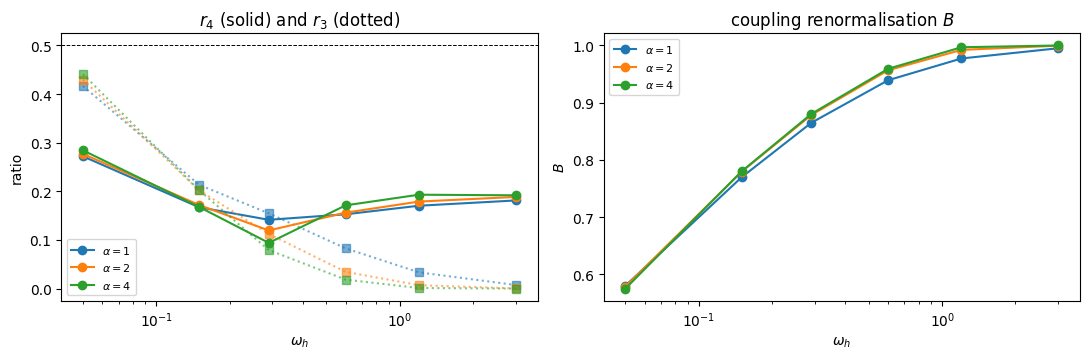

In [18]:
# r_n = rms_k ||K_n(t_k)||_F / rms_k ||K_2(t_k)||_F   (k >= 1)
r3, r4 = gp.generator_ratio(kn, 3), gp.generator_ratio(kn, 4)
rms = lambda K_: np.sqrt(np.mean(np.linalg.norm(K_[1:], axis=(1, 2))**2))
assert np.isclose(r4, rms(kn.K[4]) / rms(kn.K[2])) and np.isclose(r3, rms(kn.K[3]) / rms(kn.K[2]))
print(f'frame (alpha={alpha}, omega_h={omega_h}):  r3 = {r3:.4f}   r4 = {r4:.4f}')

alphas_s, whs = [1.0, 2.0, 4.0], [0.05, 0.15, 0.29, 0.6, 1.2, 3.0]
R3, R4, BB = (np.zeros((len(alphas_s), len(whs))) for _ in range(3))
_t0 = _time.time()
for i_, a_ in enumerate(alphas_s):
    for j_, w_ in enumerate(whs):
        f_ = gp.make_frame(p, a_, w_)
        k_ = gp.K_nodes(f_, tmax, NODE_DT, NQ, PANEL)
        R3[i_, j_], R4[i_, j_], BB[i_, j_] = gp.generator_ratio(k_, 3), gp.generator_ratio(k_, 4), f_.B
print('%d frames in %.0f s' % (R4.size, _time.time() - _t0))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.7))
for i_, a_ in enumerate(alphas_s):
    ax[0].semilogx(whs, R4[i_], 'o-', label=r'$\alpha=%g$' % a_); ax[0].semilogx(whs, R3[i_], 's:', color=ax[0].lines[-1].get_color(), alpha=0.6)
    ax[1].semilogx(whs, BB[i_], 'o-', label=r'$\alpha=%g$' % a_)
ax[0].axhline(0.5, color='k', lw=0.7, ls='--')
ax[0].set(xlabel=r'$\omega_h$', ylabel='ratio', title=r'$r_4$ (solid) and $r_3$ (dotted)'); ax[0].legend(fontsize=8)
ax[1].set(xlabel=r'$\omega_h$', ylabel='$B$', title='coupling renormalisation $B$'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 16. Assemble the full generator and propagate TCL2, +K3, +K4, TCL234

The $\mathcal K_n$ are interaction-picture objects at sparse nodes. In the Schrödinger picture ($\operatorname{vec}\rho=\mathcal P(t)\operatorname{vec}\rho_I$, $\mathcal P=\operatorname{diag}(e^{-i\Delta_\mu t})$):

$$\widehat{\mathcal K}_n(t_k)=\mathcal P(t_k)\,\mathcal K_n(t_k)\,\mathcal P(t_k)^{-1},\qquad [\widehat{\mathcal K}_n]_{\mu\nu}=e^{-i\Delta_\mu t_k}[\mathcal K_n]_{\mu\nu}e^{+i\Delta_\nu t_k}.$$

These are interpolated onto the fine grid by a cubic spline (not-a-knot) and added to the TCL2 generator:

$$\mathcal L_{\rm TCL2}=\mathcal L_2,\quad \mathcal L_{\rm K3}=\mathcal L_2+\widehat{\mathcal K}_3,\quad \mathcal L_{\rm K4}=\mathcal L_2+\widehat{\mathcal K}_4,\quad \boxed{\mathcal L_{\rm TCL234}=\mathcal L_2+\widehat{\mathcal K}_3+\widehat{\mathcal K}_4}$$

These are propagated with the same midpoint exponential rule as in Section 8. The TCL2 part is the dense trapezoid generator $\mathcal L_2$ (equal to $\mathcal K_2$ by Section 11). The cell assembles everything by hand and checks the result against the one-call driver `gp.run_frame`.

*Numerical caveat:* the node spacing must resolve the oscillation $e^{-i\Delta t}$. For large $\Gamma$ (gap $E_1-E_0\approx2$) a node spacing of 1.5 leaves an interpolation error of order $10^{-2}$ in $P_D-P_A$; check it with the convergence ladder, `python -m goa_pqme.studies.ladder`.

hand-assembled propagation == gp.run_frame for ['TCL2', 'K3', 'K4', 'TCL234']   r3=0.0343 r4=0.1561


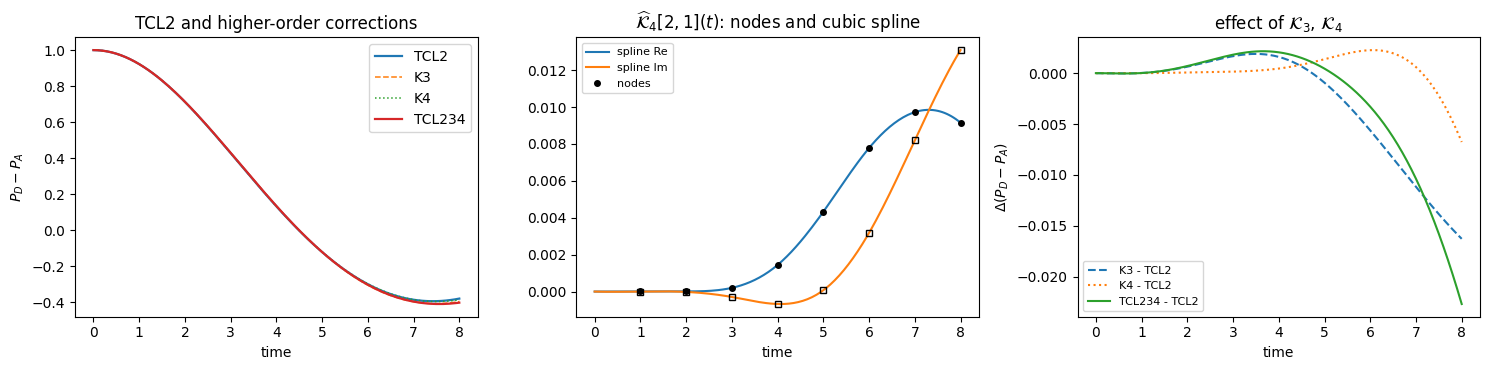

In [19]:
# L_TCL234(t) = L2(t) + spline[P K3 P^-1](t) + spline[P K4 P^-1](t) ;  vec rho_{k+1} = expm(dt (L_k + L_{k+1})/2) vec rho_k
K3s = gp.interpolate_generator(kn.t, kn.K[3], E, T)
K4s = gp.interpolate_generator(kn.t, kn.K[4], E, T)
gens = dynamics.variant_generators(tc.L, K3s, K4s)
dP = {name: gp.population_difference(fr, gp.propagate(Lv, T, rho0)) for name, Lv in gens.items()}
res = gp.run_frame(p, alpha, omega_h, gp.Numerics(node_dt=NODE_DT, nq=NQ, panel_h=PANEL, dt=dt, tmax=tmax))
for name in dP:
    assert np.allclose(dP[name], res.dP[name], atol=1e-12)
print('hand-assembled propagation == gp.run_frame for', list(dP), '  r3=%.4f r4=%.4f' % (res.r3, res.r4))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for name, st in zip(dP, ('-', '--', ':', '-')):
    ax[0].plot(T, dP[name], st, lw=1.6 if name in ('TCL2', 'TCL234') else 1.1, label=name)
    if name != 'TCL2':
        ax[2].plot(T, dP[name] - dP['TCL2'], st, label=name + ' - TCL2')
ax[0].set(xlabel='time', ylabel='$P_D-P_A$', title='TCL2 and higher-order corrections'); ax[0].legend()
ax[2].set(xlabel='time', ylabel=r'$\Delta(P_D-P_A)$', title='effect of $\\mathcal{K}_3$, $\\mathcal{K}_4$'); ax[2].legend(fontsize=8)
mu, nu = 2, 1                                                # one coherence-coupling element of K4 in the Schroedinger picture
nodes_S = liouville.to_schrodinger(kn.K[4][1:], E, kn.t[1:])[:, mu, nu]
ax[1].plot(T, K4s[:, mu, nu].real, label='spline Re'); ax[1].plot(T, K4s[:, mu, nu].imag, label='spline Im')
ax[1].plot(kn.t[1:], nodes_S.real, 'ko', ms=4, label='nodes'); ax[1].plot(kn.t[1:], nodes_S.imag, 'ks', ms=4, mfc='none')
ax[1].set(xlabel='time', title=r'$\widehat{\mathcal{K}}_4[%d,%d](t)$: nodes and cubic spline' % (mu, nu)); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 17. Code map: which function computes what?

| Physics | Equation | Function (`goa_pqme`) | Output |
|---|---|---|---|
| Secondary log discretisation | $\omega_j, c_j$ | `bath.secondary_modes` | arrays $(N-1)$ |
| Hessian diagonalisation, $R_q$, $E_r$ | §2 | `bath.normal_modes` | `BathModes(omega, R, Er)` |
| Filter | $f_q=1-e^{-(\omega/\omega_h)^\alpha}$ | `frame.polaron_filter` | $(N)$ |
| $\xi_q,x_q,B,\lambda_p,\widetilde H_S,E,U,S_a$ | §3 | `frame.make_frame` | `PolaronFrame` |
| $\phi,M,C_X$ | §4 | `PolaronFrame.phi / mixed / linear` | complex $(n_t)$ |
| Channel tensors $\mathcal C,\mathcal C^-$ | §6 | `tcl2.correlation_tensors` | $(4,4,n_t)$ |
| Rate tensors $W^{f,b}$ | §7 | `tcl2.rate_tensors` | $(n_t,4,4,2,2)$ |
| TCL2 generator $\mathcal L_2$ | §8 | `tcl2.TCL2(...).L` | $(n_t,4,4)$ |
| Multi-time bath moments | §12 | `moments.ResidualBath.moment(_at)` | complex |
| Liouville moments $\mathcal M_n$ | §10 | `tcl_higher.MomentEngine.liouville_moment` | $(N,4,4)$ |
| $\mathcal K_2,\mathcal K_3,\mathcal K_4$ (and $n_X$ classes) | §11, §13, §14 | `MomentEngine.K`, `tcl_higher.K_nodes` | `KNodes` |
| Nested Gauss–Legendre | §13 | `tcl_higher.nested_nodes` | tuples, weights |
| $r_3,r_4$ | §15 | `tcl_higher.generator_ratio` | float |
| Picture change, spline | §16 | `liouville.to_schrodinger`, `dynamics.interpolate_generator` | $(n_t,4,4)$ |
| Propagation, populations | §8, §16 | `dynamics.propagate`, `population_difference` | $\rho(t)$, $P_D-P_A$ |
| Whole frame | — | `pipeline.run_frame` / `python -m goa_pqme frame` | `FrameResult` |

### Exercises

1. Increase $y_0$ from $0.75$ to $1.5$: how do $E_r$, $\phi$, $M$ and $C_X$ change? What does *not* change?
2. Change $\omega_h$ from $0.6$ to $2$: which modes keep more linear coupling? What happens to $B$, and to $r_4$?
3. Derive $\mathcal C_{AA,DA}$ and $\mathcal C_{DA,AD}$ from $\langle X(t)D_s(0)\rangle$ and $\langle D_s(t)D_{s'}(0)\rangle$, and check them with `ResidualBath.moment_at`.
4. Show from the table in §10 that $\mathcal K_2$ is trace preserving for *any* $\mathcal C$.
5. Halve `NODE_DT` and double `NQ`: how much do $\mathcal K_4(t_{\max})$ and $P_D-P_A$ (TCL234) change? Repeat for $\Gamma=1$.
6. Using §14b, which $n_X$ class dominates $\mathcal K_4$ in a strongly dressed frame ($\omega_h=0.05$) and in a weakly dressed one ($\omega_h=3$)?

**Boundary of this notebook.** It shows how the implementation constructs TCL2, TCL3 and TCL4 and checks the internal consistency of each step: closed forms against the moment engine, $\mathcal K_2$ against the TCL2 dissipator, trace preservation, and cumulant structure. Accuracy against numerically exact dynamics (TEMPO) is the subject of `GOA_TEMPO_TCL234_workflow.ipynb`.